63


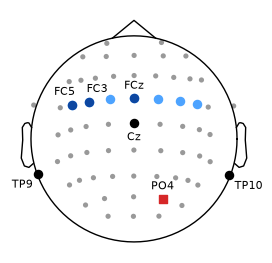

In [1]:
import re
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import mne
from config import PREPROCESSED, FIGURES
CH_FILE = PREPROCESSED / "ch_names.txt"
OUT_DIR = FIGURES
OUT_DIR.mkdir(parents=True, exist_ok=True)          # creates the folder if it doesn't exist
OUT_FILE = OUT_DIR / "electrode_layout.png"
# Appearance (adjust here)
GREY = "0.6"                 # all electrodes (0 = black, 1 = white)
FC_COLOUR = "#4DA3FF"        # fronto-central row
FC_LABEL_COLOUR = "#0D47A1"  # labelled fronto-central electrodes
OTHER_COLOUR = "black"       # Cz, TP9, TP10
REF_COLOUR = "#D62728"       # reference electrode PO4
GREY_SIZE = 14
MARKER_SIZE = 34
LABEL_SIZE = 8
SHIFT_UP = 0.15              # move all electrodes up, as a fraction of the head radius (0 = Cz centred)

# Read the channel names, allowing for one-per-line, comma-separated or b'...' formats
raw = [n for n in re.split(r"[,\s]+", CH_FILE.read_text()) if n]
ch_names = []
for n in raw:
    n = n.strip("[]")
    if n.startswith(("b'", 'b"')):
        n = n[2:]
    n = n.strip("'\"")
    if n:
        ch_names.append(n)

print(len(ch_names))                       # should be 63

# Add the reference PO4, whose trace is not stored
if "PO4" not in ch_names:
    ch_names = ch_names + ["PO4"]

info = mne.create_info(ch_names, sfreq=125.0, ch_types="eeg")
info.set_montage(mne.channels.make_standard_montage("standard_1005"), match_case=False)

# Head circle centred directly under Cz, with MNE's default head size
ch_pos = info.get_montage().get_positions()["ch_pos"]
cz = np.asarray(ch_pos["Cz"])
SPHERE = (cz[0], cz[1], 0.0, 0.095)

# Electrodes to highlight (edit these lists if needed)
FRONTO_CENTRAL = ["FC5", "FC3", "FC1", "FCz", "FC2", "FC4", "FC6"]
LABELLED = ["FC5", "FC3", "FCz", "Cz", "TP9", "TP10", "PO4"]
REFERENCE = "PO4"

# Label position for each electrode: (x offset, y offset, horizontal align, vertical align)
DEFAULT = (0, 5, "center", "bottom")
OFFSETS = {
    "FC5":  (2, 5, "right", "bottom"),
    "FC3":  (-2, 5, "left", "bottom"),
    "Cz":   (0, -6, "center", "top"),
    "TP9":  (-4, -4, "right", "top"),
    "TP10": (4, -4, "left", "top"),
}
LABEL_BOX = dict(boxstyle="round,pad=0.1", facecolor="white", edgecolor="none", alpha=0.6)

fig, ax = plt.subplots(figsize=(3.2, 3.2))
mne.viz.plot_sensors(info, kind="topomap", axes=ax, show=False, title="",
                     pointsize=GREY_SIZE, linewidth=0, sphere=SPHERE)

# 2D sensor positions, in the same order as ch_names, shifted up
coll = next(c for c in ax.collections if len(c.get_offsets()) == len(ch_names))
pos = coll.get_offsets().copy()
pos[:, 1] += SHIFT_UP * SPHERE[3]
coll.set_offsets(pos)
coll.set_facecolor(GREY)
coll.set_edgecolor("none")

idx = {name.lower(): i for i, name in enumerate(ch_names)}
def p(name):
    return pos[idx[name.lower()]]

# Fronto-central row
fc = np.array([p(n) for n in FRONTO_CENTRAL])
ax.scatter(fc[:, 0], fc[:, 1], s=MARKER_SIZE, color=FC_COLOUR, zorder=3)

# Labelled electrodes
for name in LABELLED:
    x, y = p(name)
    if name == REFERENCE:
        ax.scatter(x, y, s=MARKER_SIZE, marker="s", color=REF_COLOUR, zorder=4)
    else:
        colour = FC_LABEL_COLOUR if name in FRONTO_CENTRAL else OTHER_COLOUR
        ax.scatter(x, y, s=MARKER_SIZE, color=colour, zorder=4)
    dx, dy, ha, va = OFFSETS.get(name, DEFAULT)
    ax.annotate(name, (x, y), xytext=(dx, dy), textcoords="offset points",
                ha=ha, va=va, fontsize=LABEL_SIZE, bbox=LABEL_BOX, zorder=5)

ax.set_title("")
fig.savefig(OUT_FILE, dpi=300, bbox_inches="tight")
plt.show()

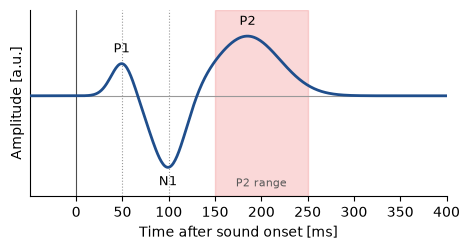

In [2]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from config import FIGURES
OUT_DIR = FIGURES
OUT_DIR.mkdir(parents=True, exist_ok=True)
OUT_FILE = OUT_DIR / "p1n1p2_schematic.png"

# Idealised waveform: sum of three Gaussian peaks (schematic only, not data)
# (latency in ms, relative amplitude, width in ms)
PEAKS = {"P1": (50, 0.45, 12), "N1": (100, -1.0, 18), "P2": (185, 0.8, 35)}

t = np.arange(-50, 401)                      # ms relative to sound onset
y = sum(a * np.exp(-0.5 * ((t - mu) / sd) ** 2) for mu, a, sd in PEAKS.values())

fig, ax = plt.subplots(figsize=(4.8, 2.6))

# P2 range and the P1/N1 latencies from Section 2.1.4
ax.axvspan(150, 250, color="lightcoral", alpha=0.3, zorder=0)
for lat in (50, 100):
    ax.axvline(lat, color="0.6", lw=0.8, ls=":", zorder=1)
ax.axhline(0, color="0.6", lw=0.8, zorder=1)
ax.axvline(0, color="0.3", lw=0.8, zorder=1)

ax.plot(t, y, color="#1F4E8C", lw=2, zorder=3)

# Peak labels placed at each peak of the plotted curve
for name, (mu, a, sd) in PEAKS.items():
    win = (t > mu - 30) & (t < mu + 30)
    i = np.argmax(y[win]) if a > 0 else np.argmin(y[win])
    tp, yp = t[win][i], y[win][i]
    ax.annotate(name, (tp, yp), xytext=(0, 6 if a > 0 else -6), textcoords="offset points",
                ha="center", va="bottom" if a > 0 else "top", fontsize=9)

ax.text(200, -1.25, "P2 range", ha="center", va="bottom", fontsize=8, color="0.35")

ax.set_xlim(-50, 400)
ax.set_ylim(-1.35, 1.15)
ax.set_xticks([0, 50, 100, 150, 200, 250, 300, 350, 400])
ax.set_xlabel("Time after sound onset [ms]")
ax.set_ylabel("Amplitude [a.u.]")
ax.set_yticks([])
for side in ("top", "right"):
    ax.spines[side].set_visible(False)

fig.tight_layout()
fig.savefig(OUT_FILE, dpi=300, bbox_inches="tight")
plt.show()

Annotations: AUNP01_annotations.json, using '/phones', 1562 phones, e.g. ['F', 'R', 'EH1', 'D', 'R', 'IH0', 'K', 'F']
Audio: AUNP01.wav, 16000 Hz
Saved to: C:\Users\frank\OneDrive\Desktop\Correlating Brain responses with Audio Features\FinalNotebook\figures\features_example.png


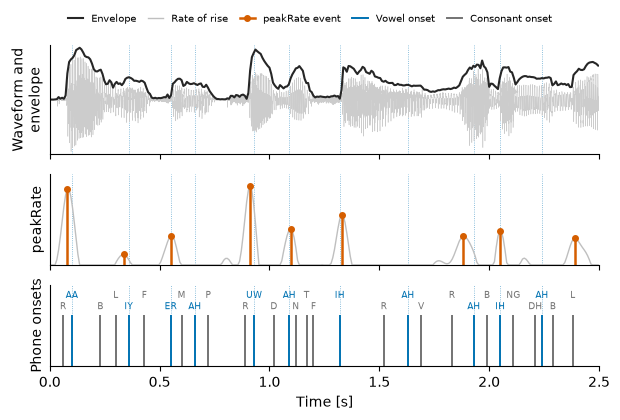

In [3]:
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.io import wavfile
from scipy.signal import butter, filtfilt, find_peaks

from config import DATA_ROOT, FIGURES
DATA = DATA_ROOT
P05 = DATA / "Preprocessed" / "P05"
AUDIO = DATA / "audiobooks"
OUT_DIR = FIGURES
OUT_DIR.mkdir(parents=True, exist_ok=True)
OUT_FILE = OUT_DIR / "features_example.png"

FS = 125
STEMS = [f"AUNP{i:02d}" for i in range(1, 9)] + [f"BROP{i:02d}" for i in range(1, 4)] + [f"FLOP{i:02d}" for i in range(1, 5)]

# Stretch of speech to show (change these to pick a clear example)
PART = 0            # chapter index 0-14 (0 = AUNP01)
T_START = 21.0      # s from the start of the chapter
T_LEN = 2.5         # s

# Colours
WAVE_COLOUR = "0.8"
ENV_COLOUR = "0.15"
PR_COLOUR = "#D55E00"
VOWEL_COLOUR = "#0072B2"
CONS_COLOUR = "0.45"

# ---- peakRate, exactly as in 05_peakRate ----
SMOOTH_HZ, MIN_DIST_MS, HEIGHT_PCT = 10.0, 100, 50
MIN_DIST = int(round(MIN_DIST_MS / 1000 * FS))
b, a = butter(3, SMOOTH_HZ / (FS / 2), btype="low")

envs, derivs = [], []
for i in range(15):
    env = np.load(P05 / f"stim_part{i:02d}.npy")
    envs.append(env)
    derivs.append(np.maximum(np.gradient(filtfilt(b, a, env)), 0.0))
threshold = float(np.percentile(np.concatenate([d[d > 0] for d in derivs]), HEIGHT_PCT))

env, deriv = envs[PART], derivs[PART]
pr_idx, _ = find_peaks(deriv, height=threshold, distance=MIN_DIST)

# ---- phone onsets from the annotation file (no timing offset) ----
SILENCE = {"", "sil", "sp", "spn", "<sil>", "sil0"}
START_KEYS = ("start", "onset", "xmin", "begin", "tmin", "start_time")
LABEL_KEYS = ("label", "phone", "text", "mark", "phoneme")

def find_intervals(obj, path=""):
    """Return the first list of (start, label) pairs found, preferring a phone tier."""
    candidates = []
    def walk(o, p):
        if isinstance(o, dict):
            if isinstance(o.get("name"), str):
                p = f"{p}<{o['name']}>"
            for k, v in o.items():
                walk(v, f"{p}/{k}")
        elif isinstance(o, list) and o:
            first = o[0]
            if isinstance(first, dict) and any(k in first for k in START_KEYS) and any(k in first for k in LABEL_KEYS):
                sk = next(k for k in START_KEYS if k in first)
                lk = next(k for k in LABEL_KEYS if k in first)
                candidates.append((p, [(float(x[sk]), str(x[lk])) for x in o]))
            elif isinstance(first, (list, tuple)) and len(first) >= 3:
                candidates.append((p, [(float(x[0]), str(x[2])) for x in o]))
            else:
                for j, v in enumerate(o):
                    walk(v, f"{p}[{j}]")
    walk(obj, path)
    if not candidates:
        raise ValueError("Could not find phone intervals in the annotation file; paste its first few entries.")
    candidates.sort(key=lambda c: "phon" not in c[0].lower())
    return candidates[0]

ann_file = next(DATA.rglob(f"{STEMS[PART]}_annotations.json"))
path, intervals = find_intervals(json.loads(ann_file.read_text()))
phones = [(t, lab.strip()) for t, lab in intervals if lab.strip().lower() not in SILENCE]
print(f"Annotations: {ann_file.name}, using '{path}', {len(phones)} phones, e.g. {[lab for _, lab in phones[:8]]}")

# ---- audio ----
wav_file = next(AUDIO.rglob(f"*{STEMS[PART]}*.wav"))
fs_audio, audio = wavfile.read(wav_file)
audio = audio.astype(float)
if audio.ndim > 1:
    audio = audio.mean(axis=1)
print(f"Audio: {wav_file.name}, {fs_audio} Hz")

# ---- window ----
t_env = np.arange(len(env)) / FS
w_env = (t_env >= T_START) & (t_env < T_START + T_LEN)
t_aud = np.arange(len(audio)) / fs_audio
w_aud = (t_aud >= T_START) & (t_aud < T_START + T_LEN)
pr_t = pr_idx / FS
pr_in = pr_idx[(pr_t >= T_START) & (pr_t < T_START + T_LEN)]
ph_in = [(t, lab) for t, lab in phones if T_START + 0.02 <= t < T_START + T_LEN - 0.02]

wave = audio[w_aud] / np.max(np.abs(audio[w_aud]))
env_w = env[w_env] / np.max(env[w_env])
der_w = deriv[w_env] / np.max(deriv[w_env])

# ---- figure ----
fig, axes = plt.subplots(3, 1, figsize=(6.3, 4.2), sharex=True,
                         gridspec_kw={"height_ratios": [1.2, 1, 0.9]})

VOWELS = {"AA", "AE", "AH", "AO", "AW", "AY", "EH", "ER", "EY", "IH", "IY", "OW", "OY", "UH", "UW"}

def is_vowel(lab):
    return lab.rstrip("012").upper() in VOWELS

for ax in axes:
    for t, lab in ph_in:
        if is_vowel(lab):
            ax.axvline(t - T_START, color=VOWEL_COLOUR, lw=0.6, ls=":", alpha=0.6, zorder=0)

# Top: waveform and envelope
ax = axes[0]
ax.plot(t_aud[w_aud] - T_START, wave, color=WAVE_COLOUR, lw=0.4)
ax.plot(t_env[w_env] - T_START, env_w, color=ENV_COLOUR, lw=1.5)
ax.set_ylim(-1.05, 1.05)
ax.set_ylabel("Waveform and\nenvelope")

# Middle: peakRate
ax = axes[1]
ax.plot(t_env[w_env] - T_START, der_w, color="0.75", lw=1)
heights = deriv[pr_in] / np.max(deriv[w_env])
ax.vlines(pr_in / FS - T_START, 0, heights, color=PR_COLOUR, lw=1.8)
ax.plot(pr_in / FS - T_START, heights, "o", color=PR_COLOUR, ms=4)
ax.set_ylim(0, 1.15)
ax.set_ylabel("peakRate")

# Bottom: phone onsets
ax = axes[2]
for k, (t, lab) in enumerate(ph_in):
    colour = VOWEL_COLOUR if is_vowel(lab) else CONS_COLOUR
    ax.vlines(t - T_START, 0, 1, color=colour, lw=1.4)
    ax.text(t - T_START, 1.08 + 0.22 * (k % 2), lab.rstrip("012"), ha="center", va="bottom",
            fontsize=6.5, color=colour)
ax.set_ylim(0, 1.6)
ax.set_ylabel("Phone onsets")

for ax in axes:
    ax.set_yticks([])
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
axes[-1].set_xlim(0, T_LEN)
axes[-1].set_xlabel("Time [s]")

handles = [
    Line2D([], [], color=ENV_COLOUR, lw=1.5, label="Envelope"),
    Line2D([], [], color="0.75", lw=1, label="Rate of rise"),
    Line2D([], [], color=PR_COLOUR, marker="o", ms=4, lw=1.8, label="peakRate event"),
    Line2D([], [], color=VOWEL_COLOUR, lw=1.4, label="Vowel onset"),
    Line2D([], [], color=CONS_COLOUR, lw=1.4, label="Consonant onset"),
]
fig.align_ylabels(axes)
fig.tight_layout(rect=(0, 0, 1, 0.94))
fig.legend(handles=handles, loc="upper center", ncol=5, fontsize=7, frameon=False,
           bbox_to_anchor=(0.5, 1.0), handlelength=1.6, columnspacing=1.2)
fig.savefig(OUT_FILE, dpi=300, bbox_inches="tight")
print("Saved to:", OUT_FILE.resolve())
plt.show()